In [ ]:
#For sequential workflows we have to use Stategraph 

In [1]:
print("hello")

hello


In [2]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [ ]:
#node in graph is always a python function => will take state as input and return state 

class BMIState(TypedDict):
    weight_kg : float
    height_m : float
    bmi : float
    category : str

In [4]:
def Calculate_BMI(state : BMIState)->BMIState:
    height = state['height_m']
    weight = state['weight_kg']
    bmi = weight/(height**2)
    state['bmi'] = round(bmi,2)
    return state

In [11]:
def Label_BMI(state : BMIState)->BMIState:
    bmi = state['bmi']
    if bmi<18.5:
        state['category'] = "Under weight"
    elif bmi<25:
        state['category'] = "Normal"
    else:
        state['category'] = "Over weight"

    return state

In [12]:
#WORKFLOW =

#DEFINE GRAPH
#ADD NODE
#ADD EDGE
#COMPILE GRAPH
#Invoke

In [13]:
#Define : Graph
graph = StateGraph(BMIState)

#add node to the graph

graph.add_node("Calculate_BMI",Calculate_BMI)
graph.add_node("Label_BMI",Label_BMI)

#add edges to the graph

graph.add_edge(START,"Calculate_BMI")
graph.add_edge("Calculate_BMI","Label_BMI")
graph.add_edge("Label_BMI",END)


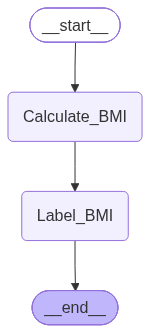

In [14]:
#compile
workflow = graph.compile()
workflow

In [15]:
initial_State = {"weight_kg":18,"height_m":18}

final_state = workflow.invoke(initial_State)

final_state

{'weight_kg': 18, 'height_m': 18, 'bmi': 0.06, 'category': 'Under weight'}